# Pre-Activity setup
PLEASE: make a local copy of this notebook in your google drive, so you can edit it without modifying the original.

First, let's download the necessary packages and data.
1. first download all the data from:
https://1drv.ms/u/c/d446169bfe3b3704/EdaggDgXpV9FvTPeaq6uK2IBvwob7NV2gRReI7jgVAlz8Q?e=qz5hNH

2. unzip locally (you should find 4 files) and upload the 4 files manually
3. once all the files are uploaded, run the following chunk



In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage

print("Setup complete. All required packages have been loaded.")

# Global plot settings
#plt.rcParams["figure.figsize"] = (14, 7)

Setup complete. All required packages have been loaded.


## To use the shared data in this folder:

Go to the shared folder biotrain2026

Select Organize --> Add shortcut

<img src="https://drive.google.com/uc?export=view&id=14UNjWLkh_HR75FFTDEIB4ZyomN3eTyr9" alt="img1" width="80%">

Go to All locations
Select My Drive, then Add

<img src="https://drive.google.com/uc?export=view&id=1_oB11wBHkGzfHoq0KgCjufYEno9AU4JG" alt="img2" width="40%">

Mount your local drive:

In [1]:
from google.colab import drive
import os
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


Change the working directory.

You should change to $\verb|/content/drive/My Drive/EMBL-EBI 2026. Gene expression group/|$

In [2]:
os.chdir('/content/drive/My Drive/Cursos/metagenomica/EMBL-EBI 2026. Gene expression group/')
!ls

Code  Data  Info  References


# 1. Introduction
This section provides an additional dataset to practice clustering methods. Cancer omics data is well-suited for this exercise, as projects like The **Cancer Genome Atlas (TCGA)** have generated high-dimensional datasets from thousands of tumors across many cancer types ([Weinstein et al., 2013](https://www.nature.com/articles/ng.2764)). The high feature-to-sample ratio in such data makes machine learning (ML) and artificial intelligence (AI) essential for analysis. These computational approaches are frequently used to identify biologically relevant patterns in cancer research ([Hutter, 2018](https://www.cell.com/cell/fulltext/S0092-8674(18)30374-X)). Specifically, clustering is an important exploratory tool used to identify novel patient subgroups based on their molecular profiles, which may not correspond to traditional disease classifications.

![fig](https://www.cell.com/cms/10.1016/j.cell.2018.03.042/asset/97589225-3dd8-4601-862b-8915c45e6c5c/main.assets/gr1_lrg.jpg)
*An infographic summarizing the scale of the effort and output from the Cancer Genome Atlas (TCGA) ([Hutter, 2018](https://www.cell.com/cell/fulltext/S0092-8674(18)30374-X))*

This notebook presents a **exploratory analysis of a pan-cancer dataset from The Cancer Genome Atlas (TCGA)**. The primary objective is to apply various unsupervised machine learning techniques, specifically clustering and dimensionality reduction, to identify patterns in high-dimensional molecular data (trancriptomics and proteomics). We will explore how these patterns correlate with clinical annotations, such as primary disease type and sample origin.

The dataset contains molecular and clinical information from a large cohort of cancer patients. Each observation (row) in the molecular data matrix corresponds to a tissue sample from an individual patient. These samples represent several categories, including primary tumors (the site of origin), solid tissue normal (adjacent non-cancerous tissue), primary blood-derived cancers, and metastatic lesions. Each feature (column) quantifies a molecular attribute; depending on the dataset, this may be the expression level of a gene or the abundance of a protein. This molecular matrix is supplemented by annotation files that provide clinical information for each sample, most notably the primary disease (the tumor's tissue of origin) and the specific sample type. For further exploration of these datasets, including the download of additional sample features, several public resources are highly recommended. The UCSC Xena browser ([https://xenabrowser.net/](https://xenabrowser.net/)) provides a platform for interactive visualization of the TCGA data. To identify and download all available raw and processed data files, the GDC Data Portal ([https://portal.gdc.cancer.gov/](https://portal.gdc.cancer.gov/)) is the primary data repository.

The analysis includes the following key steps:

Data Loading and Preparation: Importing gene expression and proteomics data along with clinical labels.
Data Cleaning and Subsetting: Preprocessing the data to handle missing values, duplicates, and reduce dimensionality for efficient analysis.

Exploratory Data Analysis (EDA): Utilizing dimensionality reduction techniques like Principal Component Analysis (PCA) and t-Distributed Stochastic Neighbor Embedding (t-SNE) to visualize the data structure.

Clustering Analysis: Applying hierarchical clustering and other methods to group samples based on their molecular profiles.

Akternative Visualizations: Using interactive plots and annotated heatmaps to interpret the results in the context of clinical information.

# **2. Gene Expression Analysis (Transcriptomics)**
In this section, we will analyze the pan-cancer gene expression dataset. A `README.md` file within the [repository](https://github.com/jbzt/cancer_data_for_cluster_and_classification) provides essential information about the study.

## **2.1. Background: The TCGA Pan-Cancer Transcriptome Dataset**
In this section, we analyze a comprehensive pan-cancer gene expression dataset derived from **The Cancer Genome Atlas (TCGA) Pan-Cancer Atlas initiative**. This landmark project systematically characterized over 20,000 primary cancer and matched normal samples across 33 cancer types ([Weinstein et al., 2013](https://doi.org/10.1038/ng.2764)). The goal was to create a complete atlas of the molecular aberrations (genomic, epigenomic, transcriptomic, and proteomic) that drive different cancers, ultimately identifying commonalities and differences across tumor lineages.

![Figure 1. A conceptual workflow of the Pan-Cancer Atlas project, illustrating the integration of multi-omic data from thousands of patient samples across dozens of cancer types to identify common and distinct molecular patterns.](https://media.springernature.com/lw685/springer-static/image/art%3A10.1186%2Fs12967-023-03907-z/MediaObjects/12967_2023_3907_Fig1_HTML.png)

*Figure 1. Conceptual workflow of the Pan-Cancer Atlas project, illustrating the integration of multi-omic data to identify molecular patterns. Source: National Cancer Institute.*

The transcriptomic data used here was generated via **RNA-Sequencing (RNA-Seq)**, a high-throughput technology that quantifies the abundance of messenger RNA (mRNA) in a biological sample. This provides a snapshot of the active genes at a specific moment. For the TCGA project, RNA-Seq was primarily performed on tissue samples from **primary solid tumors**. In many cases, matched **solid tissue normal** samples were also collected from the same patient, providing a crucial baseline for identifying cancer-specific expression changes. For blood cancers like Acute Myeloid Leukemia (LAML), the samples consisted of peripheral blood.

**Data Normalization:** The raw RNA-Seq read counts undergo significant computational processing before they are suitable for analysis. The data in TCGA's "Level 3" archives, which are commonly used for this type of analysis, have already been processed through a standardized pipeline. This typically includes alignment to a reference genome and normalization to account for technical variations, such as differences in sequencing depth between samples. Common normalization methods used for TCGA data include FPKM (Fragments Per Kilobase of transcript per Million mapped reads) and TPM (Transcripts Per Million), which make gene expression levels comparable across different samples and genes ([Zhao et al., 2021](https://doi.org/10.1016/j.csbj.2021.09.006)). The dataset we are using is pre-processed, allowing us to proceed directly to exploratory analysis.

Required packages:

## 2.2. Data Loading
Load the pan-cancer gene expression data.

In [3]:
!pip install pyreadr
import pyreadr   # pip install pyreadr  — required to read .RDS files

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.3/788.3 kB 10.8 MB/s eta 0:00:00


In [4]:
local_path = "Data/pan_cancer_dataset.RDS"
result = pyreadr.read_r(local_path)
# pyreadr returns an OrderedDict; take the first (and only) data frame
df = list(result.values())[0]

## 2.3. Initial Data Inspection and Cleaning
Inspect the dimensions and structure of the dataset. We will then perform essential steps, such as checking for duplicate gene entries and setting the gene names as row identifiers for easier data manipulation.

In [5]:
# Display dimensions (rows, columns)
print("Shape:", df.shape)

# Show the top-left corner of the dataframe
print(df.iloc[:4, :4])

# Verify that there are no duplicate gene names
print("Any duplicated genes:", df["gene"].duplicated().any())

# Set the 'gene' column as the index and drop the original column
df = df.set_index("gene")

# Confirm the changes
print(df.iloc[:4, :4])

Shape: (20530, 10460)
        gene  TCGA-S9-A7J2-01  TCGA-G3-A3CH-11  TCGA-EK-A2RE-01
0  ARHGEF10L          10.9576          11.0186           9.7106
1      HIF3A           4.8099           5.3847           2.8888
2      RNF17           0.4657           0.0000           0.4192
3      RNF10          11.2675          11.6690          11.4903
Any duplicated genes: False
           TCGA-S9-A7J2-01  TCGA-G3-A3CH-11  TCGA-EK-A2RE-01  TCGA-44-6778-01
gene                                                                         
ARHGEF10L          10.9576          11.0186           9.7106           9.6205
HIF3A               4.8099           5.3847           2.8888           7.9642
RNF17               0.4657           0.0000           0.4192           1.5378
RNF10              11.2675          11.6690          11.4903          11.8432


## 2.3. Loading Labels
Next, load the clinical labels data, which contains labels for each sample, including the primary disease and sample type (e.g., primary tumor, metastatic).

In [8]:
labels_path = "Data/labels.tsv"
labels = pd.read_csv(labels_path, sep="\t", na_values="")

# Rename the fourth column to 'primary_disease' for clarity
labels.columns.values[3] = "primary_disease"

print(labels.head())

            sample  sample_type_id            sample_type  \
0  TCGA-D3-A1QA-07             7.0  Additional Metastatic   
1  TCGA-DE-A4MD-06             6.0             Metastatic   
2  TCGA-J8-A3O2-06             6.0             Metastatic   
3  TCGA-J8-A3YH-06             6.0             Metastatic   
4  TCGA-EM-A2P1-06             6.0             Metastatic   

           primary_disease  
0  skin cutaneous melanoma  
1        thyroid carcinoma  
2        thyroid carcinoma  
3        thyroid carcinoma  
4        thyroid carcinoma  


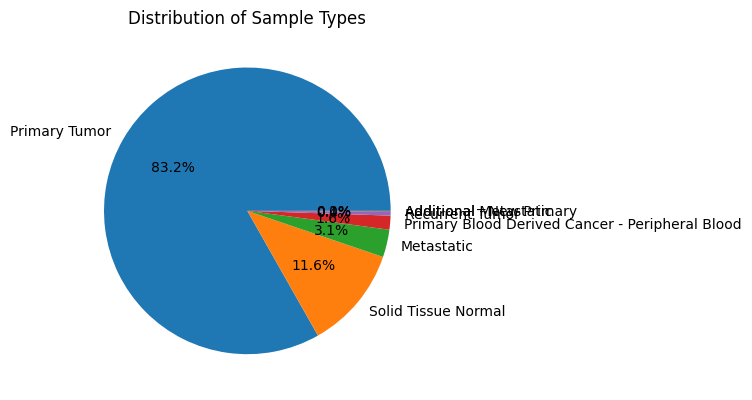

In [ ]:
# Pie chart: distribution of sample types
sample_type_counts = labels["sample_type"].value_counts()
fig, ax = plt.subplots()
ax.pie(sample_type_counts, labels=sample_type_counts.index, autopct="%1.1f%%")
ax.set_title("Distribution of Sample Types")
plt.tight_layout()
plt.show()

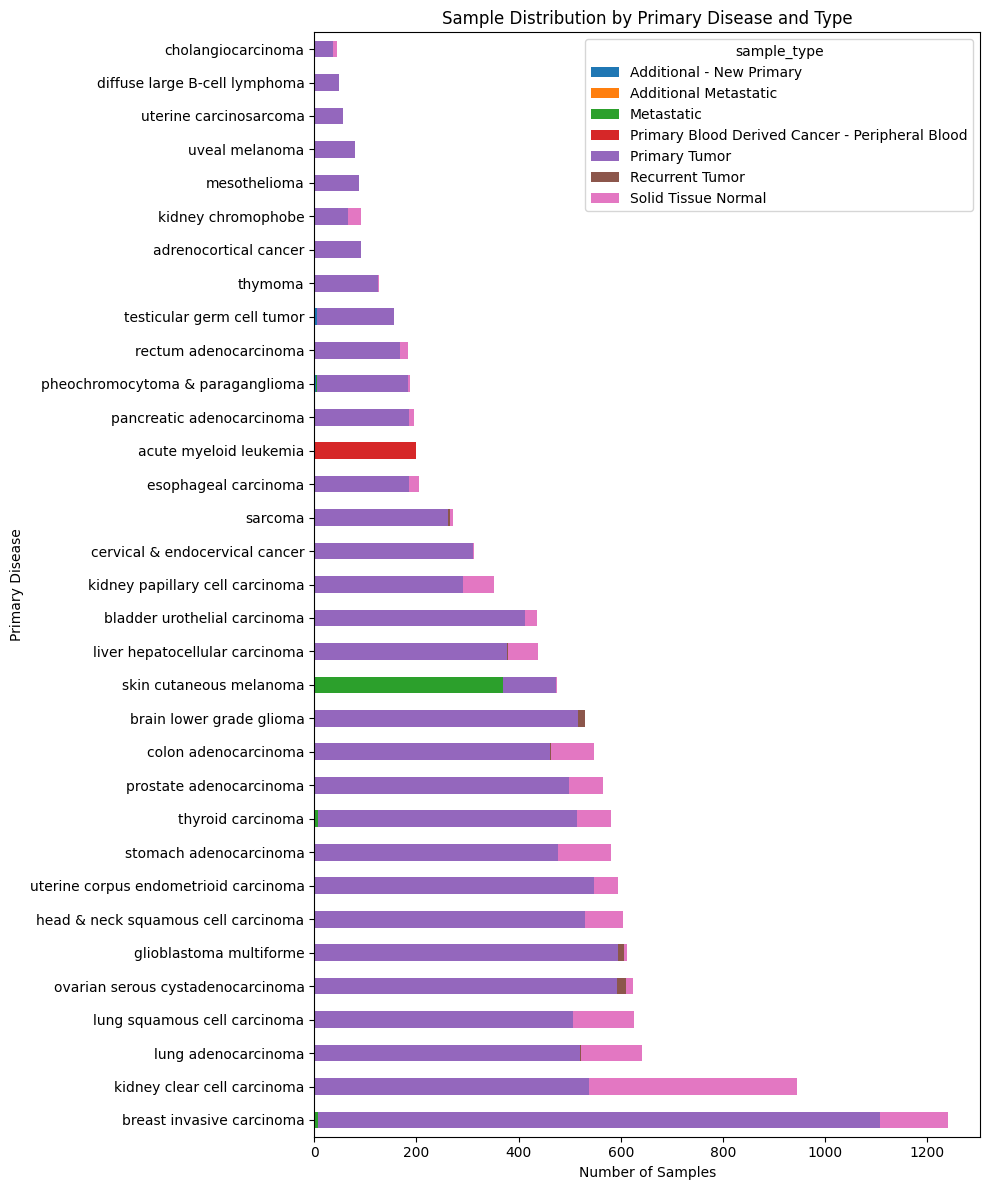

In [ ]:
# Stacked bar chart: sample types per primary disease
df_plot = (
    labels
    .groupby(["primary_disease", "sample_type"])
    .size()
    .reset_index(name="n")
)
total_order = (
    df_plot.groupby("primary_disease")["n"]
    .sum()
    .sort_values(ascending=False)
    .index
)
pivot = df_plot.pivot_table(
    index="primary_disease", columns="sample_type", values="n", fill_value=0
)
pivot = pivot.loc[total_order]
pivot.plot(kind="barh", stacked=True, figsize=(10, 12))
plt.title("Sample Distribution by Primary Disease and Type")
plt.xlabel("Number of Samples")
plt.ylabel("Primary Disease")
plt.tight_layout()
plt.show()



## 2.4. Subsetting for Efficient Analysis
To ensure computational efficiency during this initial exploratory phase, we will work with a random subset of the data. This is a pragmatic approach for rapidly prototyping our analytical pipeline.

However, this method involves a trade-off between performance and potential information loss. You are encouraged to **experiment** by adjusting the `n.genes` and `n.samples` variables below to observe these effects directly.

**Key Considerations:**

* **Reducing Gene Count (`n.genes`):** While this speeds up computation, it risks excluding key genes that define important biological subtypes, potentially leading to an incomplete interpretation.
* **Reducing Sample Count (`n.samples`):** This lowers statistical power and creates the risk that findings may not be generalizable to the entire patient cohort, especially if rare subtypes are omitted by chance.


In [ ]:
rng = np.random.default_rng(123)

n_genes = 200
n_samples = 1000

gene_idx = rng.choice(df.shape[0], size=n_genes, replace=False)
sample_idx = rng.choice(df.shape[1], size=n_samples, replace=False)

df = df.iloc[gene_idx, sample_idx]

# Transpose: observations (samples) as rows, features (genes) as columns
df = df.T

print(df.iloc[:4, :4])


gene             C4orf47   DPPA2  SLCO1B3  ZNF595
TCGA-67-3771-01   4.2661  5.1509   0.0000  9.7800
TCGA-V1-A8MU-01   2.6371  0.0000   1.7540  7.6187
TCGA-06-2567-01   5.8882  0.0000   0.0000  7.1047
TCGA-DD-A4NH-01   2.0814  0.0000   5.8198  7.1675


## 2.5. Aligning Annotation with Expression Data
To ensure that the clinical labels correspond to the samples in our expression matrix, we will align the `labels` dataframe with the subsetted `df` dataframe based on sample IDs (row names).

In [ ]:
labels = labels.set_index("sample")
labels = labels.loc[df.index]

print(labels.shape, df.shape)
print(labels.head())

(1000, 3) (1000, 200)
                 sample_type_id    sample_type                 primary_disease
TCGA-67-3771-01             1.0  Primary Tumor             lung adenocarcinoma
TCGA-V1-A8MU-01             1.0  Primary Tumor         prostate adenocarcinoma
TCGA-06-2567-01             1.0  Primary Tumor         glioblastoma multiforme
TCGA-DD-A4NH-01             1.0  Primary Tumor  liver hepatocellular carcinoma
TCGA-FG-A60K-01             1.0  Primary Tumor        brain lower grade glioma


## 2.6. Dataset Summary

Let's review the number of samples available for each cancer type in our final subset. **You can modify the code to add plots similar to the ones in section 2.3.**

In [ ]:
summary = (
    labels["primary_disease"]
    .value_counts()
    .rename_axis("primary_disease")
    .reset_index(name="n_obs")
)
print(summary)

                          primary_disease  n_obs
0               breast invasive carcinoma    125
1             kidney clear cell carcinoma     71
2                       thyroid carcinoma     61
3                     lung adenocarcinoma     58
4            lung squamous cell carcinoma     57
5     head & neck squamous cell carcinoma     52
6                 prostate adenocarcinoma     48
7            bladder urothelial carcinoma     48
8          liver hepatocellular carcinoma     43
9                brain lower grade glioma     42
10                 stomach adenocarcinoma     39
11                skin cutaneous melanoma     37
12                   colon adenocarcinoma     32
13         cervical & endocervical cancer     30
14                                sarcoma     29
15      ovarian serous cystadenocarcinoma     26
16        kidney papillary cell carcinoma     23
17                   esophageal carcinoma     22
18              pancreatic adenocarcinoma     20
19                 a

## 2.7. Dimensionality Reduction

High-dimensional data, where the number of features (genes) vastly exceeds the number of observations (samples), is difficult to interpret directly. **Dimensionality reduction** is a useful process of transforming this data into a low-dimensional space. The goal is to capture the most important patterns and relationships in the data, making it suitable for visualization and clustering analysis.

### 2.7.1. Principal Component Analysis (PCA)
Principal Component Analysis (PCA) is a linear technique for dimensionality reduction. It transforms data into a new set of uncorrelated variables called **Principal Components (PCs)**, which are ordered by the amount of variance they explain. The first component (PC1) accounts for the most variance, PC2 for the second most, and so on ([Jolliffe, 2002](https://link.springer.com/book/10.1007/b98835)). Plotting the initial PCs allows for visualization of the main sources of variation in the data.

Clustering molecular data identifies relationships not apparent from standard pathology. The method can stratify patients **within a single cancer type** into biological subgroups; for instance, the definition of breast cancer's intrinsic subtypes now guides treatment decisions ([Perou et al., 2000](https://doi.org/10.1038/35021093)). It can also reveal similarities **between different tumor types** based on shared molecular drivers, independent of tissue of origin ([Hoadley et al., 2018](https://www.cell.com/cell/fulltext/S0092-8674(18)30374-X)). This pan-cancer insight supports 'basket trials', where targeted therapies are administered based on molecular markers like `NTRK` fusions rather than the cancer's anatomical site ([Drilon et al., 2018](https://doi.org/10.1056/NEJMoa1714448)).

In [ ]:
# Filter out genes (columns) with zero total expression to avoid errors
df_nonzero = df.loc[:, df.sum(axis=0) > 0]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_nonzero)

pca = PCA(n_components=3, random_state=123)
pca_coords = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(pca_coords, columns=["PC1", "PC2", "PC3"], index=df.index)
pca_df["disease"] = labels.loc[pca_df.index, "primary_disease"].values
pca_df["type"] = labels.loc[pca_df.index, "sample_type"].values

# PC1 vs PC2 — colored by primary disease
fig = px.scatter(
    pca_df, x="PC1", y="PC2", color="disease",
    title="PCA of Gene Expression by Primary Disease"
)
fig.show()

# PC2 vs PC3 — colored by primary disease
fig = px.scatter(
    pca_df, x="PC2", y="PC3", color="disease",
    title="PCA (PC2 vs PC3) by Primary Disease"
)
fig.show()

In [ ]:
# PC1 vs PC2 — colored by sample type
fig = px.scatter(
    pca_df, x="PC1", y="PC2", color="type",
    title="PCA of Gene Expression by Sample Type"
)
fig.show()


- What is the most prominent pattern in the PC1 vs. PC2 plot? Do samples generally group by their `primary_disease`?
- Can you find different cancer types that cluster closely together?
- Based on the observed sample distribution, what main biological factor do you think **PC1** and **PC2** represents?

To summarize the visualization, only the centroid of each group can be plotted. This approach reduces visual clutter from individual data points, clarifying the global relationships and the average position of each category within the principal component space.

In [ ]:
# --- PCA Centroids ---
pca_centroids = (
    pca_df.groupby("disease")[["PC1", "PC2", "PC3"]]
    .mean()
    .reset_index()
)
print(pca_centroids)


                                  disease       PC1       PC2       PC3
0                  acute myeloid leukemia -7.192080  5.794361 -2.748952
1                   adrenocortical cancer  0.443362 -6.562952 -0.173977
2            bladder urothelial carcinoma  4.371097  1.042065 -1.838903
3                brain lower grade glioma -7.943465 -5.493715 -4.069749
4               breast invasive carcinoma -2.491131  1.527971 -1.060666
5          cervical & endocervical cancer  6.027580  1.325543 -1.380378
6                      cholangiocarcinoma  1.840311 -5.774176  0.992215
7                    colon adenocarcinoma  3.721969  1.423302  0.845097
8           diffuse large B-cell lymphoma  5.163481  0.243519  1.914622
9                    esophageal carcinoma  0.132716  4.886789 -2.965103
10                glioblastoma multiforme -3.831068 -2.081731 -1.032121
11    head & neck squamous cell carcinoma  5.211602  3.883930 -0.488442
12                     kidney chromophobe  0.575463 -5.746848 -0

In [ ]:
fig = px.scatter(
    pca_centroids, x="PC1", y="PC2", color="disease", text="disease",
    title="PCA Centroids by Primary Disease (PC1 vs PC2)",
    labels={"PC1": "Principal Component 1", "PC2": "Principal Component 2"}
)
fig.update_traces(marker_size=12, textposition="top center")
fig.update_layout(showlegend=False)
fig.show()


### Molecular similarity between cancer types
By first calculating an average gene expression profile for each disease, a representative "molecular signature" can be created. These signatures are then correlated to build a similarity matrix, which is visualized as a clustered heatmap. This final visualization reveals a molecular taxonomy of cancers, allowing us to identify families of tumors that share transcriptomic features, irrespective of their anatomical site of origin, and to discover potentially unexpected relationships between different diseases.


In [ ]:
# Combine expression data with disease labels
df_with_labels = df.copy()
df_with_labels.insert(0, "disease", labels["primary_disease"].values)

# Calculate the average gene expression profile for each cancer type
cancer_centroids = (
    df_with_labels
    .groupby("disease")
    .mean(numeric_only=True)
)

# Calculate Pearson correlation between cancer types
# Rows are cancer types, columns are genes, so transpose before corr()
cancer_correlation_matrix = cancer_centroids.T.corr(method="pearson")

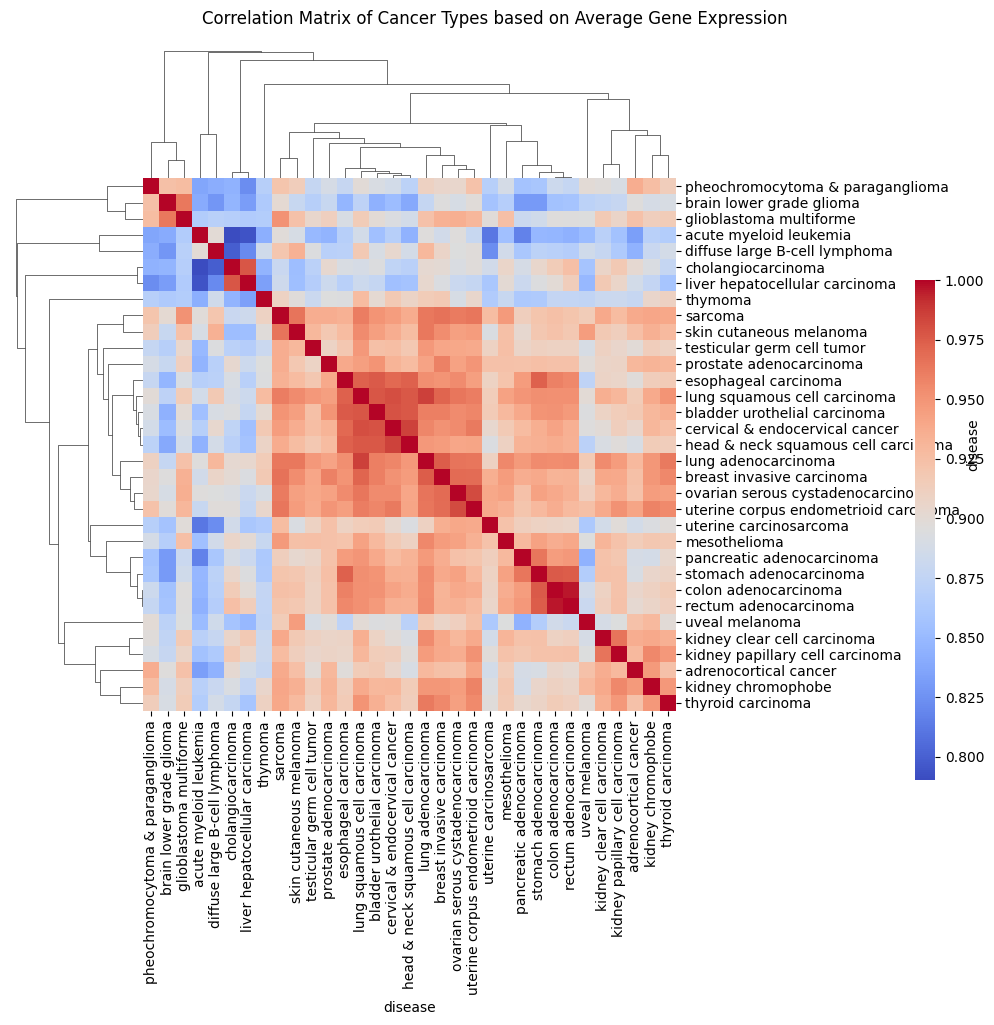

In [ ]:
# Distance matrix equivalent to as.dist(1 - cancer_correlation_matrix)
cancer_distance_matrix = 1 - cancer_correlation_matrix

# Clustered heatmap
g = sns.clustermap(
    cancer_correlation_matrix,
    row_linkage=None,
    col_linkage=None,
    metric="correlation",
    method="average",
    cmap="coolwarm",
    #cmap=sns.color_palette(["blue", "white", "red"], as_cmap=True),
    figsize=(10, 10),
    xticklabels=True,
    yticklabels=True,
    cbar_pos=(0.92, 0.25, 0.02, 0.5)
)

g.fig.suptitle(
    "Correlation Matrix of Cancer Types based on Average Gene Expression",
    y=1.02
)

plt.show()

### **t-Distributed Stochastic Neighbor Embedding (t-SNE)**

t-Distributed Stochastic Neighbor Embedding ([t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html)) is a non-linear method used to visualize high-dimensional data. Unlike PCA, which preserves global variance, t-SNE is designed to preserve the local neighborhood structure of the data, making it effective for identifying distinct clusters.

Operationally, t-SNE is a probabilistic algorithm that models pairwise sample similarities in a low-dimensional space. This differs from PCA's deterministic, linear transformation. Consequently, the interpretation of a t-SNE plot is also different: while the grouping of points into clusters is significant, the relative size of these clusters and the distances **between** them are generally not meaningful. For a detailed guide on its interpretation, refer to ["How to Use t-SNE Effectively"](https://distill.pub/2016/misread-tsne/).

In biological analysis, t-SNE is used to identify or confirm discrete subgroups within a larger data population based on their molecular profiles. It is often applied as a complementary method to PCA. While PCA can reveal broad data structures, t-SNE can further resolve these large groups to identify more subtle sub-clusters, which can aid in generating hypotheses about rare or previously unclassified molecular subtypes.

you can modify the `perplexity` and `max_iter` hyperparameters to assess the sensitivity of the algorithm and the stability of the resulting visualization.

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=123,verbose=1)
tsne_coords = tsne.fit_transform(df.values)

tsne_df = pd.DataFrame(tsne_coords, columns=["tSNE1", "tSNE2"], index=df.index)
tsne_df["disease"] = labels.loc[tsne_df.index, "primary_disease"].values
tsne_df["type"] = labels.loc[tsne_df.index, "sample_type"].values

# Colored by primary disease
fig = px.scatter(
    tsne_df, x="tSNE1", y="tSNE2", color="disease",
    title="t-SNE Colored by Primary Disease"
)
fig.show()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1000 samples in 0.001s...
[t-SNE] Computed neighbors for 1000 samples in 0.146s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1000
[t-SNE] Mean sigma: 7.965812
[t-SNE] KL divergence after 250 iterations with early exaggeration: 64.877007
[t-SNE] KL divergence after 1000 iterations: 0.721852


In [ ]:

# Colored by sample type
fig = px.scatter(
    tsne_df, x="tSNE1", y="tSNE2", color="type",
    title="t-SNE Colored by Sample Type"
)
fig.show()

- How does the t-SNE plot compare to the PCA plot in its ability to separate the different cancer types? Does t-SNE generally produce more distinct and compact clusters for each `primary_disease`?
- Does the t-SNE plot resolve groups into smaller, more defined sub-clusters?
- Do certain cancer types consistently appear in the same region of the plot, suggesting local similarities in the data structure?

### 2.10.3. K-Means Clustering on t-SNE Coordinates

K-Means clustering is an unsupervised learning algorithm that partitions data into a predefined number of clusters (`k`). It aims to minimize the variance within each cluster. Here, we'll apply K-Means to the t-SNE reduced dimensions to see if it can identify meaningful groups based on the `disease` and `type` labels.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Prepare data for clustering (t-SNE coordinates only)
X_tsne = tsne_df[['tSNE1', 'tSNE2']].values

# --- K-Means based on 'disease' ---
# Determine number of clusters based on unique diseases
k_disease = tsne_df['disease'].nunique()
print(f"Number of unique diseases: {k_disease}")

kmeans_disease = KMeans(n_clusters=k_disease, random_state=123, n_init=10) # n_init is important for robust results
kmeans_disease_labels = kmeans_disease.fit_predict(X_tsne)
tsne_df['kmeans_disease_cluster'] = kmeans_disease_labels

# Visualize K-Means clustering results based on disease
fig_kmeans_disease = px.scatter(
    tsne_df, x='tSNE1', y='tSNE2', color=tsne_df['kmeans_disease_cluster'].astype(str),
    title=f'K-Means Clustering (k={k_disease}) by Disease on t-SNE',
    labels={'color': 'K-Means Cluster'},
    hover_data={'kmeans_disease_cluster': True, 'disease': True} # Add disease to hover
)
fig_kmeans_disease.show()

# Evaluate clustering with Silhouette Score
silhouette_avg_disease = silhouette_score(X_tsne, kmeans_disease_labels)
print(f"Silhouette Score for K-Means (based on disease): {silhouette_avg_disease:.3f}")

# --- K-Means based on 'type' ---
# Determine number of clusters based on unique sample types
k_type = tsne_df['type'].nunique()
print(f"Number of unique sample types: {k_type}")

kmeans_type = KMeans(n_clusters=k_type, random_state=123, n_init=10) # n_init is important for robust results
kmeans_type_labels = kmeans_type.fit_predict(X_tsne)
tsne_df['kmeans_type_cluster'] = kmeans_type_labels

# Visualize K-Means clustering results based on sample type
fig_kmeans_type = px.scatter(
    tsne_df, x='tSNE1', y='tSNE2', color=tsne_df['kmeans_type_cluster'].astype(str),
    title=f'K-Means Clustering (k={k_type}) by Sample Type on t-SNE',
    labels={'color': 'K-Means Cluster'},
    hover_data={'kmeans_type_cluster': True, 'type': True} # Add type to hover
)
fig_kmeans_type.show()

# Evaluate clustering with Silhouette Score
silhouette_avg_type = silhouette_score(X_tsne, kmeans_type_labels)
print(f"Silhouette Score for K-Means (based on type): {silhouette_avg_type:.3f}")

Number of unique diseases: 33


Silhouette Score for K-Means (based on disease): 0.535
Number of unique sample types: 6


Silhouette Score for K-Means (based on type): 0.464


### 2.10.4. DBSCAN Clustering on t-SNE Coordinates

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is a density-based clustering algorithm. It groups together points that are closely packed together, marking as outliers points that lie alone in low-density regions. Unlike K-Means, DBSCAN does not require specifying the number of clusters beforehand and can find arbitrarily shaped clusters.

Key parameters for DBSCAN are:
- `eps`: The maximum distance between two samples for one to be considered as in the neighborhood of the other.
- `min_samples`: The number of samples (or total weight) in a neighborhood for a point to be considered as a core point. This includes the point itself.

We will start with some reasonable default values. You may need to experiment with these parameters (`eps` and `min_samples`) to find the best clustering for your data.


In [ ]:
from sklearn.cluster import DBSCAN

# Perform DBSCAN clustering on t-SNE coordinates
# Adjust eps and min_samples as needed for your data
dbscan = DBSCAN(eps=3.0, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_tsne)
tsne_df['dbscan_cluster'] = dbscan_labels

# Visualize DBSCAN clustering results
fig_dbscan = px.scatter(
    tsne_df, x='tSNE1', y='tSNE2', color=tsne_df['dbscan_cluster'].astype(str),
    title='DBSCAN Clustering on t-SNE',
    labels={'color': 'DBSCAN Cluster'},
    hover_data={'dbscan_cluster': True, 'disease': True, 'type': True} # Add disease and type to hover
)
fig_dbscan.show()

# Evaluate clustering (Note: Silhouette Score is not ideal for DBSCAN with noise, but can give an indication)
# Exclude noise points (-1 label) for silhouette calculation if they exist
if len(set(dbscan_labels)) > 1 and -1 in dbscan_labels:
    silhouette_avg_dbscan = silhouette_score(
        X_tsne[dbscan_labels != -1], dbscan_labels[dbscan_labels != -1]
    )
    print(f"Silhouette Score for DBSCAN (excluding noise): {silhouette_avg_dbscan:.3f}")
elif len(set(dbscan_labels)) > 1 and -1 not in dbscan_labels:
    silhouette_avg_dbscan = silhouette_score(X_tsne, dbscan_labels)
    print(f"Silhouette Score for DBSCAN: {silhouette_avg_dbscan:.3f}")
else:
    print("Cannot calculate Silhouette Score for DBSCAN (only one cluster or all noise).")

print("Number of DBSCAN clusters found (excluding noise):", len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0))
print("Number of noise points (-1 label):", list(dbscan_labels).count(-1))

Silhouette Score for DBSCAN (excluding noise): 0.411
Number of DBSCAN clusters found (excluding noise): 18
Number of noise points (-1 label): 8


### 2.8. Further Visualization Strategies

When dealing with many categories, standard plots can become cluttered. Here are two strategies to enhance visualization.

#### 2.8.1. Improving Legend Layout

For plots with numerous labels, moving the legend to the bottom and arranging it in multiple rows can provide more space for the plot itself.

In [ ]:
fig = px.scatter(
    tsne_df, x="tSNE1", y="tSNE2", color="disease",
    title="t-SNE with Optimized Legend"
)
fig.update_layout(
    legend=dict(
        orientation="h", yanchor="top", y=-0.2,
        xanchor="left", x=0, font=dict(size=8)
    )
)
fig.show()


### 2.9. Focused PCA on Selected Cancer Types
To improve interpretability, we can perform PCA on a smaller subset of cancer types. This can help reveal subtype-specific patterns that might be obscured in the pan-cancer analysis.

#### 2.9.1. Random Subset of Cancer Types
The labels to be explored can be selected at random; the quantity can be modified using the `n.labels` variable.

In [ ]:
rng2 = np.random.default_rng(123)
diseases = labels["primary_disease"].unique()
n_labels = 10
labels_to_keep = rng2.choice(diseases, size=n_labels, replace=False)

samples_to_keep = labels[labels["primary_disease"].isin(labels_to_keep)].index
df_sub = df.loc[samples_to_keep]

# Keep only columns with non-zero variance to prevent errors during scaling
df_sub = df_sub.loc[:, df_sub.var(axis=0) != 0]

scaler2 = StandardScaler()
pca2 = PCA(n_components=2, random_state=123)
pca2_df = pd.DataFrame(
    pca2.fit_transform(scaler2.fit_transform(df_sub)),
    columns=["PC1", "PC2"],
    index=df_sub.index,
)
pca2_df["disease"] = labels.loc[pca2_df.index, "primary_disease"].values

fig = px.scatter(
    pca2_df, x="PC1", y="PC2", color="disease",
    title="PCA on a Random Subset of 10 Cancer Types"
)
fig.show()


### K-Means Clustering on PCA2 Coordinates

Applying K-Means clustering to the PCA-reduced dimensions (`pca2_df`) to identify groups based on the `disease` labels within the subsetted cancer types. The number of clusters `k` will be determined by the number of unique diseases in this subset.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Prepare data for clustering (PCA2 coordinates only)
X_pca2 = pca2_df[['PC1', 'PC2']].values

# --- K-Means based on 'disease' in the subset ---
# Determine number of clusters based on unique diseases in pca2_df
k_disease_pca2 = pca2_df['disease'].nunique()
print(f"Number of unique diseases in subset: {k_disease_pca2}")

kmeans_disease_pca2 = KMeans(n_clusters=k_disease_pca2, random_state=123, n_init=10)
kmeans_disease_pca2_labels = kmeans_disease_pca2.fit_predict(X_pca2)
pca2_df['kmeans_disease_cluster'] = kmeans_disease_pca2_labels

# Visualize K-Means clustering results based on disease in the subset
fig_kmeans_disease_pca2 = px.scatter(
    pca2_df, x='PC1', y='PC2', color=pca2_df['kmeans_disease_cluster'].astype(str),
    title=f'K-Means Clustering (k={k_disease_pca2}) by Disease on PCA2',
    labels={'color': 'K-Means Cluster'},
    hover_data={'kmeans_disease_cluster': True, 'disease': True} # Add disease to hover
)
fig_kmeans_disease_pca2.show()

# Evaluate clustering with Silhouette Score
silhouette_avg_disease_pca2 = silhouette_score(X_pca2, kmeans_disease_pca2_labels)
print(f"Silhouette Score for K-Means (based on disease in subset): {silhouette_avg_disease_pca2:.3f}")

Number of unique diseases in subset: 10


Silhouette Score for K-Means (based on disease in subset): 0.352


### DBSCAN Clustering on PCA2 Coordinates

Now, we apply DBSCAN to the `pca2_df` to find density-based clusters within the selected cancer types. Again, default parameters for `eps` and `min_samples` are used initially, and these might require tuning for optimal results.

In [ ]:
from sklearn.cluster import DBSCAN

# Perform DBSCAN clustering on PCA2 coordinates
# Adjust eps and min_samples as needed for your data
dbscan_pca2 = DBSCAN(eps=1, min_samples=3) # Using the same initial parameters as for t-SNE
dbscan_pca2_labels = dbscan_pca2.fit_predict(X_pca2)
pca2_df['dbscan_cluster'] = dbscan_pca2_labels

# Visualize DBSCAN clustering results
fig_dbscan_pca2 = px.scatter(
    pca2_df, x='PC1', y='PC2', color=pca2_df['dbscan_cluster'].astype(str),
    title='DBSCAN Clustering on PCA2',
    labels={'color': 'DBSCAN Cluster'},
    hover_data={'dbscan_cluster': True, 'disease': True} # Corrected: 'type' is not in pca2_df
)
fig_dbscan_pca2.show()

# Evaluate clustering (Note: Silhouette Score is not ideal for DBSCAN with noise, but can give an indication)
# Exclude noise points (-1 label) for silhouette calculation if they exist
if len(set(dbscan_pca2_labels)) > 1 and -1 in dbscan_pca2_labels:
    silhouette_avg_dbscan_pca2 = silhouette_score(
        X_pca2[dbscan_pca2_labels != -1], dbscan_pca2_labels[dbscan_pca2_labels != -1]
    )
    print(f"Silhouette Score for DBSCAN (excluding noise) on PCA2: {silhouette_avg_dbscan_pca2:.3f}")
elif len(set(dbscan_pca2_labels)) > 1 and -1 not in dbscan_pca2_labels:
    silhouette_avg_dbscan_pca2 = silhouette_score(X_pca2, dbscan_pca2_labels)
    print(f"Silhouette Score for DBSCAN on PCA2: {silhouette_avg_dbscan_pca2:.3f}")
else:
    print("Cannot calculate Silhouette Score for DBSCAN on PCA2 (only one cluster or all noise).")

print("Number of DBSCAN clusters found on PCA2 (excluding noise):", len(set(dbscan_pca2_labels)) - (1 if -1 in dbscan_pca2_labels else 0))
print("Number of noise points (-1 label) on PCA2:", list(dbscan_pca2_labels).count(-1))

Silhouette Score for DBSCAN (excluding noise) on PCA2: -0.106
Number of DBSCAN clusters found on PCA2 (excluding noise): 8
Number of noise points (-1 label) on PCA2: 43


### 2.9.2. User-Defined Subset of Cancer Types
Specific cancer types can be selected for focused analysis. A list of available labels is printed for reference, and the `labels_to_keep` variable can be modified to specify which cancers to visualize.

In [ ]:
print(sorted(labels["primary_disease"].unique()))

['acute myeloid leukemia', 'adrenocortical cancer', 'bladder urothelial carcinoma', 'brain lower grade glioma', 'breast invasive carcinoma', 'cervical & endocervical cancer', 'cholangiocarcinoma', 'colon adenocarcinoma', 'diffuse large B-cell lymphoma', 'esophageal carcinoma', 'glioblastoma multiforme', 'head & neck squamous cell carcinoma', 'kidney chromophobe', 'kidney clear cell carcinoma', 'kidney papillary cell carcinoma', 'liver hepatocellular carcinoma', 'lung adenocarcinoma', 'lung squamous cell carcinoma', 'mesothelioma', 'ovarian serous cystadenocarcinoma', 'pancreatic adenocarcinoma', 'pheochromocytoma & paraganglioma', 'prostate adenocarcinoma', 'rectum adenocarcinoma', 'sarcoma', 'skin cutaneous melanoma', 'stomach adenocarcinoma', 'testicular germ cell tumor', 'thymoma', 'thyroid carcinoma', 'uterine carcinosarcoma', 'uterine corpus endometrioid carcinoma', 'uveal melanoma']


In [ ]:
labels_to_keep2 = [
    "thymoma",
    "thyroid carcinoma",
    "uterine carcinosarcoma",
    "uterine corpus endometrioid carcinoma",
    "cervical & endocervical cancer",
]
samples_to_keep2 = labels[labels["primary_disease"].isin(labels_to_keep2)].index
df_sub2 = df.loc[samples_to_keep2]

valid_cols2 = (df_sub2.sum(axis=0) > 0) & (df_sub2.var(axis=0) != 0)
df_sub2 = df_sub2.loc[:, valid_cols2]

scaler3 = StandardScaler()
pca3 = PCA(n_components=2, random_state=123)
pca3_df = pd.DataFrame(
    pca3.fit_transform(scaler3.fit_transform(df_sub2)),
    columns=["PC1", "PC2"],
    index=df_sub2.index,
)
pca3_df["disease"] = labels.loc[pca3_df.index, "primary_disease"].values

fig = px.scatter(
    pca3_df, x="PC1", y="PC2", color="disease",
    title="PCA on a Specific Subset of Cancer Types"
)
fig.show()


## 2.10. Distance-Based Analyses

Here we compute dissimilarity matrices and use them for clustering and ordination.

### 2.10.1. Distance Matrix Computation

We will calculate different distance metrics to explore sample relationships.
* **Euclidean**: Standard distance in geometric space. Sensitive to magnitude.
* **Bray-Curtis**: Based on abundance data, sensitive to composition.
* **Jaccard**: Based on presence/absence, measures dissimilarity in community composition.

**Bray-Curtis Dissimilarity**

Bray-Curtis dissimilarity is a statistic used to quantify the compositional dissimilarity between two different sites or communities. It is often used in ecology to compare the abundance of species or features between two samples. The formula is:

$$BC = \frac{\sum |x_i - y_i|}{\sum (x_i + y_i)}$$

Where:
- $x_i$ and $y_i$ are the abundances (or counts) of feature $i$ in sample X and sample Y, respectively.
- The numerator is the sum of absolute differences between the abundances of each feature.
- The denominator is the sum of the total abundances in both samples.

Bray-Curtis ranges from 0 (samples are identical) to 1 (samples share no common features, or common features have vastly different abundances). It is sensitive to both the presence/absence and the abundance of features.

*Example:*

Let's consider two communities (Sample X and Sample Y) with the counts of four different species (Species A, B, C, D):

- **Sample X:** (A=10, B=5, C=0, D=8)
- **Sample Y:** (A=8, B=0, C=12, D=8)

\begin{array}{|l|c|c|c|c|c|}
\hline
\textbf{Species} & \textbf{A} & \textbf{B} & \textbf{C} & \textbf{D} & \textbf{Total}\\
\hline
\textbf{Sample X ($x_i$)} & 10 & 5 & 0 & 8 & 23 \\
\textbf{Sample Y ($y_i$)} & 8 & 0 & 12 & 8 & 28 \\
\textbf{$|x_i - y_i|$} & $|10-8|=2$ & $|5-0|=5$ & $|0-12|=12$ & $|8-8|=0$ & $\sum |x_i - y_i| = 19$ \\
\textbf{$(x_i + y_i)$} & $10+8=18$ & $5+0=5$ & $0+12=12$ & $8+8=16$ & $\sum (x_i + y_i) = 51$ \\
\hline
\end{array}

BC = $\frac{19}{51}$ $\approx$ 0.373

This value reflects a moderate dissimilarity based on species abundances. It considers both shared species and differences in their quantities.


**Jaccard Dissimilarity**

Jaccard dissimilarity measures the dissimilarity between finite sample sets. It is typically used for presence/absence (binary) data, focusing on whether items are shared or unique between two sets. The formula is:

$$J = 1 - \frac{|A \cap B|}{|A \cup B|}$$

Where:
- $|A \cap B|$ is the number of features common to both set A and set B (intersection).
- $|A \cup B|$ is the total number of unique features present in either set A or set B (union).

Jaccard dissimilarity ranges from 0 (sets are identical, all features are shared) to 1 (sets are entirely disjoint, sharing no common features).

*Example:*

Let's consider two communities (Community 1 and Community 2) with the presence (1) or absence (0) of four different species:

- **Community 1 (Presence vector $P_1$):** [1, 1, 0, 1] (Species 1, 2, and 4 are present)
- **Community 2 (Presence vector $P_2$):** [1, 0, 1, 1] (Species 1, 3, and 4 are present)

\begin{array}{|l|c|c|c|c|c|}
\hline
\textbf{Species} & \textbf{1} & \textbf{2} & \textbf{3} & \textbf{4} \\
\hline
\textbf{Community 1 ($P_1$)} & 1 & 1 & 0 & 1 \\
\textbf{Community 2 ($P_2$)} & 1 & 0 & 1 & 1 \\
\textbf{Intersection ($P_1 \cap P_2$)} & 1 & 0 & 0 & 1 & $|\textbf{Intersection}| = 2$ \\
\textbf{Union ($P_1 \cup P_2$)} & 1 & 1 & 1 & 1 & $|\textbf{Union}| = 4$ \\
\hline
\end{array}

Jaccard Index ($J_{idx}$) = $\frac{|\text{Intersection}|}{|\text{Union}|} = \frac{2}{4} = 0.5$

Jaccard Dissimilarity ($J$) = $1 - J_{idx} = 1 - 0.5 = 0.5$

This value indicates the dissimilarity based purely on the presence or absence of species. A higher value means fewer shared species.


In [ ]:
dist_euc_c = pdist(df.values, metric="euclidean")
dist_bray_c = pdist(df.values, metric="braycurtis")
dist_jacc_c = pdist((df.values > 1).astype(float), metric="jaccard")

### 2.10.2. Hierarchical Clustering and Heatmap

Hierarchical clustering builds a tree-like structure (dendrogram) of samples based on their similarity. We visualize the clustering result alongside a heatmap of the expression data.

In [ ]:
# Perform hierarchical clustering for each distance metric
hc_bray = linkage(dist_bray_c, method="average")
hc_euclidean = linkage(dist_euc_c, method="average")
hc_jaccard = linkage(dist_jacc_c, method="average")

In [ ]:
# Create an annotation dataframe for the heatmap columns
samples = df.index

annotation_col = pd.DataFrame({
    "SampleType": labels.loc[samples, "sample_type"],
    "Disease": labels.loc[samples, "primary_disease"]
}, index=samples)

annotation_col

,SampleType,Disease
TCGA-67-3771-01,Primary Tumor,lung adenocarcinoma
TCGA-V1-A8MU-01,Primary Tumor,prostate adenocarcinoma
TCGA-06-2567-01,Primary Tumor,glioblastoma multiforme
TCGA-DD-A4NH-01,Primary Tumor,liver hepatocellular carcinoma
TCGA-FG-A60K-01,Primary Tumor,brain lower grade glioma
...,...,...
TCGA-AO-A1KR-01,Primary Tumor,breast invasive carcinoma
TCGA-AK-3460-01,Primary Tumor,kidney clear cell carcinoma
TCGA-OR-A5JT-01,Primary Tumor,adrenocortical cancer
TCGA-BP-4760-01,Primary Tumor,kidney clear cell carcinoma


In [ ]:
# Convert annotations to colors
sample_type_palette = dict(
    zip(
        annotation_col["SampleType"].unique(),
        sns.color_palette("Set2", annotation_col["SampleType"].nunique())
    )
)

disease_palette = dict(
    zip(
        annotation_col["Disease"].unique(),
        sns.color_palette("tab20", annotation_col["Disease"].nunique())
    )
)

col_colors = pd.DataFrame({
    "SampleType": annotation_col["SampleType"].map(sample_type_palette),
    "Disease": annotation_col["Disease"].map(disease_palette)
}, index=annotation_col.index)

In [ ]:
def plot_clustered_heatmap(column_linkage, title):
    g = sns.clustermap(
        df.T,
        row_cluster=True,
        col_cluster=True,
        col_linkage=column_linkage,
        col_colors=col_colors,
        xticklabels=False,
        yticklabels=True,
        cmap="vlag",
        figsize=(14, 14)
    )

    g.fig.suptitle(title, y=1.02)
    plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/matrix.py:560: UserWarning:

Clustering large matrix with scipy. Installing `fastcluster` may give better performance.



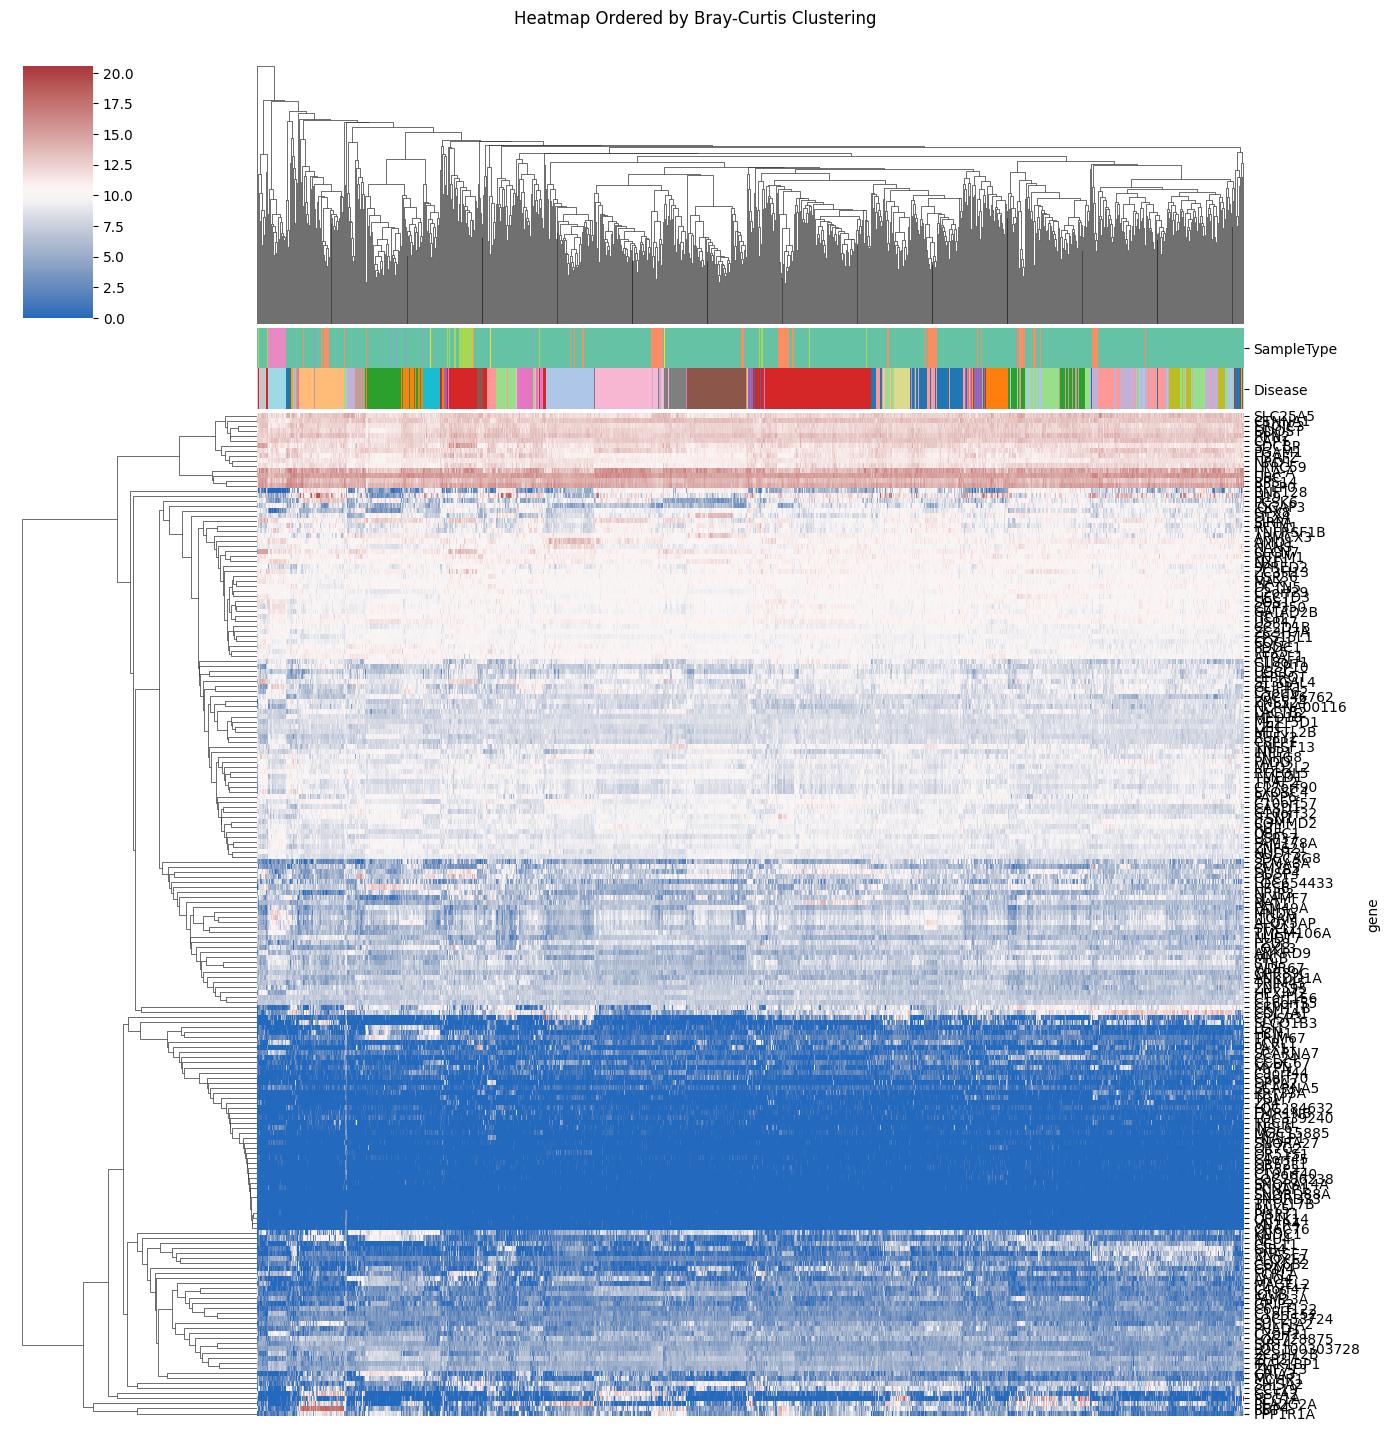

In [ ]:
# Heatmap ordered by Bray-Curtis clustering
plot_clustered_heatmap(
    hc_bray,
    "Heatmap Ordered by Bray-Curtis Clustering"
)


/usr/local/lib/python3.12/dist-packages/seaborn/matrix.py:560: UserWarning:

Clustering large matrix with scipy. Installing `fastcluster` may give better performance.



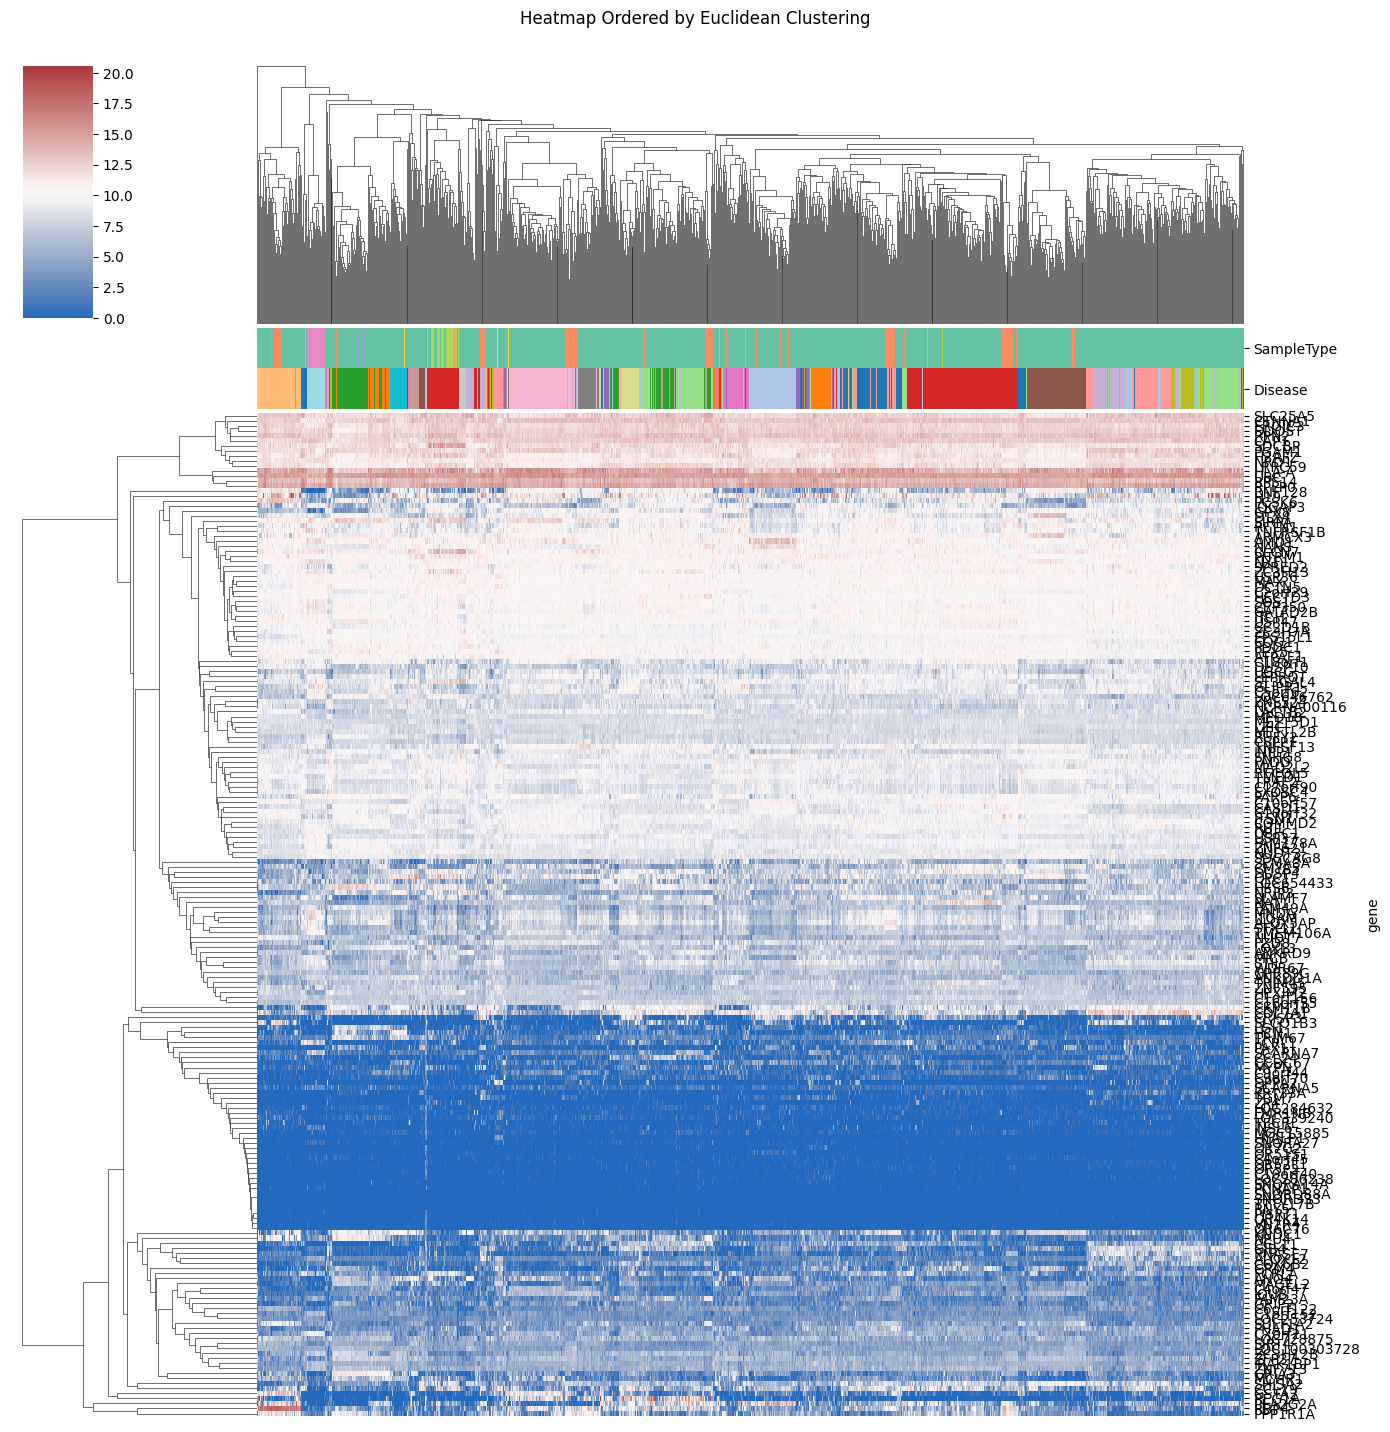

In [ ]:

# Heatmap ordered by Euclidean clustering
plot_clustered_heatmap(
    hc_euclidean,
    "Heatmap Ordered by Euclidean Clustering"
)

/usr/local/lib/python3.12/dist-packages/seaborn/matrix.py:560: UserWarning:

Clustering large matrix with scipy. Installing `fastcluster` may give better performance.



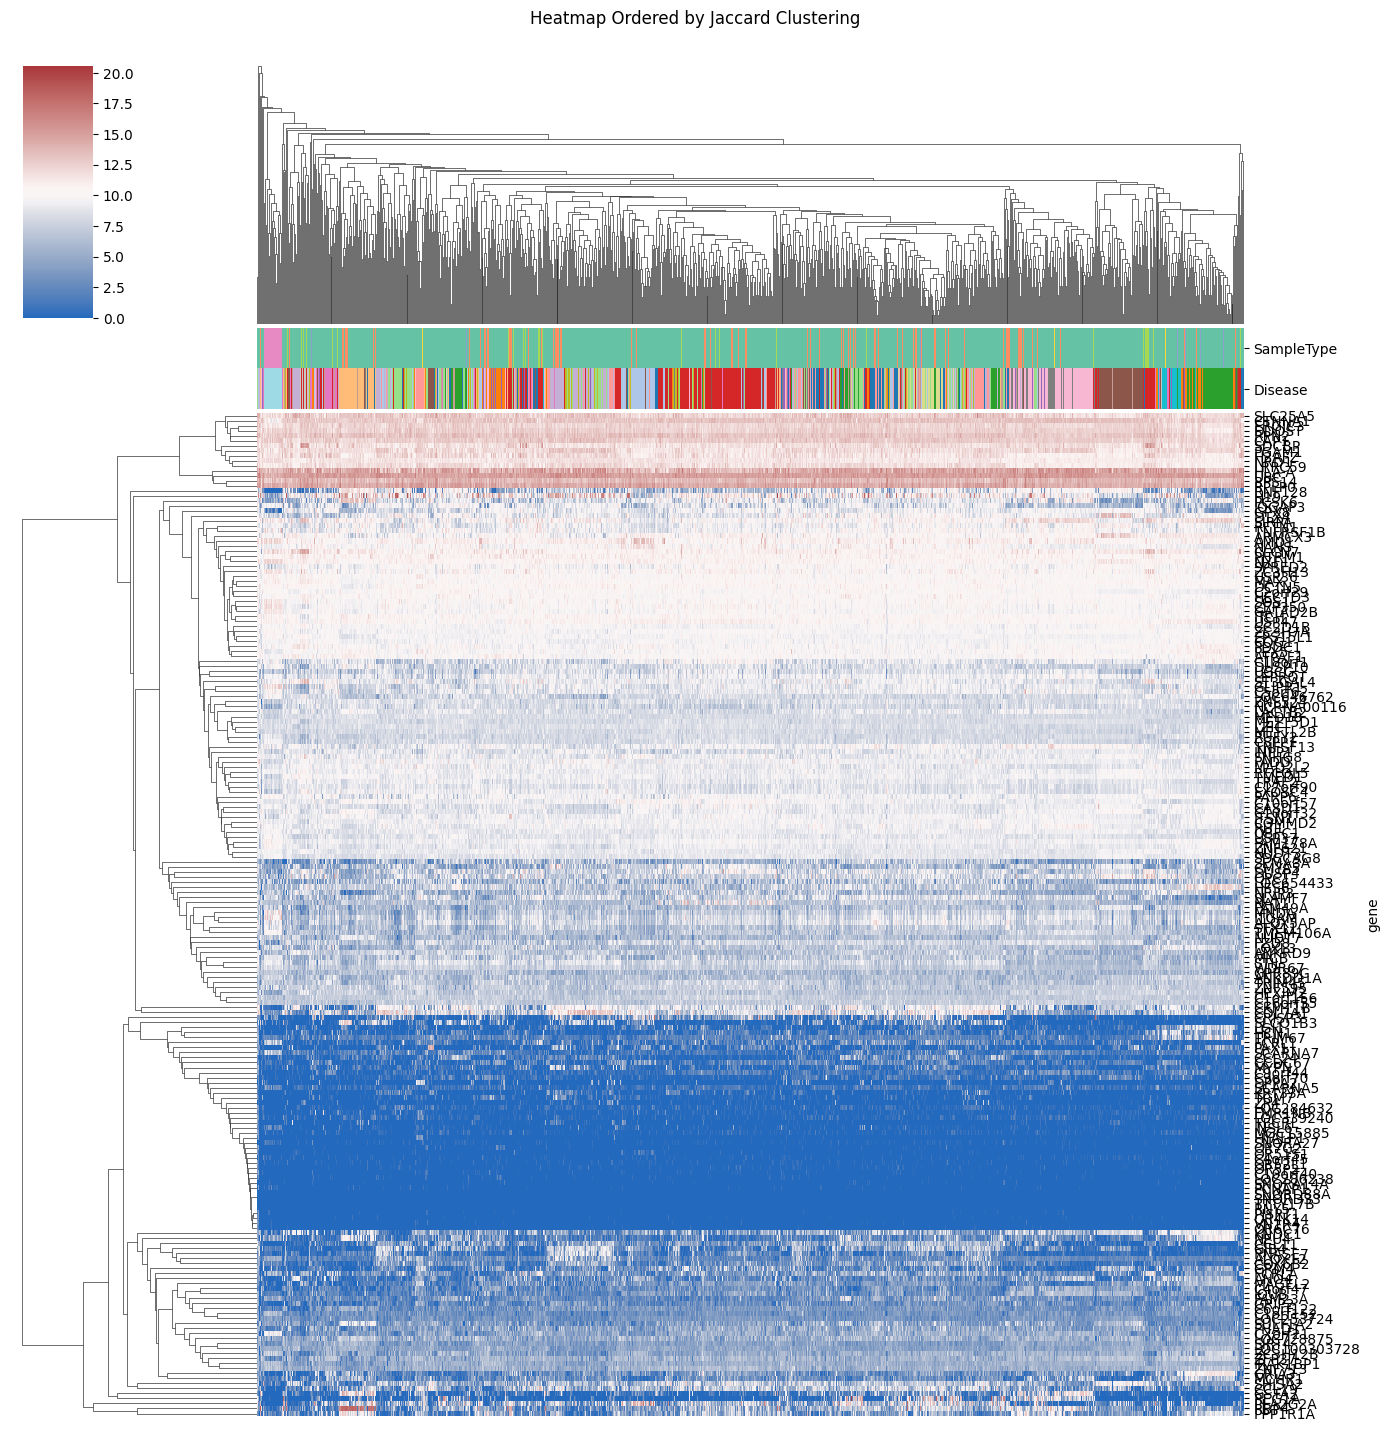

In [ ]:
# Heatmap ordered by Jaccard clustering
plot_clustered_heatmap(
    hc_jaccard,
    "Heatmap Ordered by Jaccard Clustering"
)

# 3. Proteomics Analysis

Here, we will replicate parts of the previous analysis using proteomics data to investigate if similar sample patterns emerge at the protein level.

## 3.1. Background: TCGA Proteomics Data

The proteomics data used in this study were generated using the Reverse Phase Protein Array (RPPA) platform. This high-throughput antibody-based technique quantifies the abundance of total and modified proteins in tumor lysates. For the TCGA Pan-Cancer Atlas project, samples were analyzed at the MD Anderson Cancer Center. The platform measured approximately 200-300 proteins, selected for their relevance in cancer signaling pathways. The raw data underwent extensive quality control and were normalized to account for variations in protein loading, producing the Replicate-Based Normalization (RBN) values used here ([Liu et al., 2013](https://pmc.ncbi.nlm.nih.gov/articles/PMC4213190/)). This process ensures that protein abundance levels are comparable across the thousands of samples in the cohort ([Akbani et al., 2014](https://www.nature.com/articles/ncomms4887)).

## 3.2. Rationale for Proteomics Analysis

While transcriptomics provides a comprehensive view of gene expression, mRNA abundance is often an imperfect proxy for protein abundance and cellular function. The correlation between mRNA and their corresponding protein products is surprisingly modest due to complex post-transcriptional, translational, and post-translational regulatory mechanisms ([Vogel and Marcotte, 2012](ttps://www.nature.com/articles/nrg3185)). Proteins, not transcripts, are the primary functional molecules that execute cellular processes, act as drug targets, and form the machinery of the cell. Therefore, directly measuring the proteome provides a more direct snapshot of the active biological pathways and the functional state of the tumor, complementing the information derived from the transcriptome.

## 3.3. Expected Concordance with Transcriptomics

We should not expect the clustering results from proteomics to be identical to those from transcriptomics. The overall correlation between mRNA and protein levels across large-scale cancer datasets is typically moderate, with squared Pearson correlation coefficients ($R^2$) often ranging from 0.2 to 0.4 ([Zhang et al., 2014](https://www.nature.com/articles/nature13438)). This discordance is biologically meaningful, reflecting the impact of protein translation and degradation rates which vary significantly across genes and samples. Consequently, while some broad patterns corresponding to tissue of origin may be conserved, proteomics-based clustering is likely to reveal distinct sample subgroups driven by post-transcriptional regulation and differences in signaling pathway activity that are not visible at the RNA level.

## 3.4. Data Loading and Preparation

We load the proteomics data and the same clinical labels, then align them to ensure sample correspondence.

In [10]:
proteomics_path = "Data/pan_cancer_proteomics.txt"
proteomics = pd.read_csv(proteomics_path, sep="\t", index_col=0)

# Transpose so that samples are rows and proteins are columns
df_proteomics = proteomics.T

# Reload the full labels file to match all possible samples
labels_full = pd.read_csv("Data/labels.tsv", sep="\t", na_values="")
labels_full.columns.values[3] = "primary_disease"
labels_full = labels_full.set_index("sample")

# Find the common samples and align both matrices
common_samples = df_proteomics.index.intersection(labels_full.index)
df_proteomics = df_proteomics.loc[common_samples]
labels_proteomics = labels_full.loc[common_samples]

print(df_proteomics.shape)
print(labels_proteomics.shape)
df_proteomics

(3454, 131)
(3454, 3)


Sample,1433EPSILON,4EBP1,4EBP1PS65,4EBP1PT37T46,53BP1,ACCPS79,ACC1,AKT,AKTPS473,AKTPT308,...,XRCC1,YAP,YAPPS127,YB1,YB1PS102,JNKPT183Y185,PAI1,MTORPS2448,ASNS,EGFR
TCGA-27-1833-01,0.354159,-0.765668,-0.200527,0.536203,-0.831080,0.028515,-0.662501,0.184653,1.062793,-0.510832,...,-0.231142,0.354492,-0.682578,-0.584139,0.326244,0.293156,1.800741,-0.039113,-0.513292,1.643135
TCGA-A5-A0GI-01,0.250009,-0.374590,0.195072,-0.298304,1.006317,0.327914,-0.040188,-0.007285,2.599809,2.169297,...,-0.204339,-0.058810,0.469751,-0.136670,-0.012109,-0.083342,-0.606477,0.194955,0.013131,0.090169
TCGA-BP-4165-01,0.222598,-0.380307,0.264028,-0.543908,-1.920805,-1.027610,-1.897745,-0.099745,0.133892,0.071053,...,-0.054197,0.397443,0.462954,-1.199005,-0.235836,0.168086,-0.540144,-0.109511,-1.097720,0.489403
TCGA-EY-A1GF-01,-0.048706,0.108869,-0.195315,-0.462706,0.706779,0.197589,0.030334,0.020560,3.032617,2.328308,...,-0.011672,0.021926,0.391847,-0.194302,-0.080818,-0.162695,-0.786541,-0.169739,-0.177251,0.197568
TCGA-CZ-4863-01,0.152346,0.084013,0.502963,-0.188861,-0.364346,-0.638009,-1.151583,-0.063761,0.293035,-0.389747,...,-0.323296,0.292710,0.576496,-0.522901,0.076435,0.098300,-0.156868,-0.006106,-1.016233,0.631362
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-CN-4728-01,-0.035999,0.154903,-0.530181,-1.667369,-0.798627,-0.612192,-1.142845,-0.050514,-0.581228,0.077635,...,-0.020080,0.972278,0.244166,-0.354045,0.198059,0.835581,0.847519,0.194198,-0.833161,0.775326
TCGA-B5-A0JZ-01,0.078950,-0.481774,0.022419,-0.742721,1.002955,0.207907,0.214270,0.051118,2.065414,2.194598,...,0.083053,0.238749,0.524353,0.288916,-0.123260,-0.420778,-0.709096,-0.401134,-0.349594,0.195724
TCGA-CV-7091-01,-0.199311,0.951466,0.003105,0.160255,-1.217582,-0.282502,-0.296047,-0.037299,-1.246533,-0.979511,...,-0.415263,0.114555,-0.213228,-0.406002,0.045264,0.002247,0.950301,-0.379659,-0.000230,0.449081
TCGA-FI-A2EY-01,0.120568,-0.946360,-0.172938,-0.636034,0.241778,2.347894,2.536922,-0.142597,-1.121332,-0.565509,...,0.310209,0.294693,1.285490,-0.502757,0.253016,0.171777,0.060052,0.047219,0.003859,0.355927


## 3.5. Dimensionality Reduction for Proteomics

We will now apply PCA and t-SNE to the proteomics data.

### 3.5.1. PCA on Proteomics Data


In [ ]:
prot_valid_mask = (df_proteomics.sum(axis=0) > 0) & df_proteomics.notna().all(axis=0)
df_prot_valid = df_proteomics.loc[:, prot_valid_mask]

scaler_prot = StandardScaler()
pca_prot = PCA(n_components=2, random_state=123)
pca_prot_df = pd.DataFrame(
    pca_prot.fit_transform(scaler_prot.fit_transform(df_prot_valid)),
    columns=["PC1", "PC2"],
    index=df_prot_valid.index,
)
pca_prot_df["disease"] = labels_proteomics.loc[pca_prot_df.index, "primary_disease"].values
pca_prot_df["type"] = labels_proteomics.loc[pca_prot_df.index, "sample_type"].values

fig = px.scatter(
    pca_prot_df, x="PC1", y="PC2", color="disease",
    title="PCA of Proteomics Data",
    labels={"PC1": "Principal Component 1", "PC2": "Principal Component 2"}
)
fig.show()

### 3.5.2. t-SNE on Proteomics Data

In [ ]:
tsne_prot = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=123,
                 verbose=1)
tsne_prot_coords = tsne_prot.fit_transform(df_prot_valid.values)

tsne_prot_df = pd.DataFrame(
    tsne_prot_coords, columns=["tSNE1", "tSNE2"],
    index=df_prot_valid.index,
)
tsne_prot_df["disease"] = labels_proteomics.loc[tsne_prot_df.index, "primary_disease"].values

fig = px.scatter(
    tsne_prot_df, x="tSNE1", y="tSNE2", color="disease",
    title="t-SNE of Proteomics Data",
    labels={"tSNE1": "t-SNE 1", "tSNE2": "t-SNE 2"}
)
fig.show()

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 3454 samples in 0.001s...
[t-SNE] Computed neighbors for 3454 samples in 0.212s...
[t-SNE] Computed conditional probabilities for sample 1000 / 3454
[t-SNE] Computed conditional probabilities for sample 2000 / 3454
[t-SNE] Computed conditional probabilities for sample 3000 / 3454
[t-SNE] Computed conditional probabilities for sample 3454 / 3454
[t-SNE] Mean sigma: 1.360667
[t-SNE] KL divergence after 250 iterations with early exaggeration: 73.451599
[t-SNE] KL divergence after 1000 iterations: 1.525487


### 3.5.3. K-Means Clustering on Proteomics t-SNE Coordinates

Applying K-Means clustering to the t-SNE reduced dimensions of the proteomics data to identify groups based on the `disease` labels. The number of clusters `k` will be determined by the number of unique diseases.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Prepare data for clustering (proteomics t-SNE coordinates only)
X_tsne_prot = tsne_prot_df[['tSNE1', 'tSNE2']].values

# --- K-Means based on 'disease' ---
# Determine number of clusters based on unique diseases
k_disease_prot = tsne_prot_df['disease'].nunique()
print(f"Number of unique diseases in proteomics t-SNE: {k_disease_prot}")

kmeans_disease_prot = KMeans(n_clusters=k_disease_prot, random_state=123, n_init=10)
kmeans_disease_prot_labels = kmeans_disease_prot.fit_predict(X_tsne_prot)
tsne_prot_df['kmeans_disease_cluster'] = kmeans_disease_prot_labels

# Visualize K-Means clustering results based on disease
fig_kmeans_disease_prot = px.scatter(
    tsne_prot_df, x='tSNE1', y='tSNE2', color=tsne_prot_df['kmeans_disease_cluster'].astype(str),
    title=f'K-Means Clustering (k={k_disease_prot}) by Disease on Proteomics t-SNE',
    labels={'color': 'K-Means Cluster'},
    hover_data={'kmeans_disease_cluster': True, 'disease': True} # Add disease to hover
)
fig_kmeans_disease_prot.show()

# Evaluate clustering with Silhouette Score
silhouette_avg_disease_prot = silhouette_score(X_tsne_prot, kmeans_disease_prot_labels)
print(f"Silhouette Score for K-Means (based on disease in proteomics t-SNE): {silhouette_avg_disease_prot:.3f}")

Number of unique diseases in proteomics t-SNE: 11


Silhouette Score for K-Means (based on disease in proteomics t-SNE): 0.500


### 3.5.4. DBSCAN Clustering on Proteomics t-SNE Coordinates

Applying DBSCAN to the t-SNE reduced dimensions of the proteomics data to find density-based clusters.

In [ ]:
from sklearn.cluster import DBSCAN

# Perform DBSCAN clustering on proteomics t-SNE coordinates
dbscan_prot_tsne = DBSCAN(eps=2, min_samples=5) # Default values, can be tuned
dbscan_prot_tsne_labels = dbscan_prot_tsne.fit_predict(X_tsne_prot)
tsne_prot_df['dbscan_cluster'] = dbscan_prot_tsne_labels

# Visualize DBSCAN clustering results
fig_dbscan_prot_tsne = px.scatter(
    tsne_prot_df, x='tSNE1', y='tSNE2', color=tsne_prot_df['dbscan_cluster'].astype(str),
    title='DBSCAN Clustering on Proteomics t-SNE',
    labels={'color': 'DBSCAN Cluster'},
    hover_data={'dbscan_cluster': True, 'disease': True} # Add disease to hover
)
fig_dbscan_prot_tsne.show()

# Evaluate clustering (excluding noise points if any)
if len(set(dbscan_prot_tsne_labels)) > 1 and -1 in dbscan_prot_tsne_labels:
    silhouette_avg_dbscan_prot_tsne = silhouette_score(
        X_tsne_prot[dbscan_prot_tsne_labels != -1], dbscan_prot_tsne_labels[dbscan_prot_tsne_labels != -1]
    )
    print(f"Silhouette Score for DBSCAN (excluding noise) on Proteomics t-SNE: {silhouette_avg_dbscan_prot_tsne:.3f}")
elif len(set(dbscan_prot_tsne_labels)) > 1 and -1 not in dbscan_prot_tsne_labels:
    silhouette_avg_dbscan_prot_tsne = silhouette_score(X_tsne_prot, dbscan_prot_tsne_labels)
    print(f"Silhouette Score for DBSCAN on Proteomics t-SNE: {silhouette_avg_dbscan_prot_tsne:.3f}")
else:
    print("Cannot calculate Silhouette Score for DBSCAN on Proteomics t-SNE (only one cluster or all noise).")

print("Number of DBSCAN clusters found on Proteomics t-SNE (excluding noise):", len(set(dbscan_prot_tsne_labels)) - (1 if -1 in dbscan_prot_tsne_labels else 0))
print("Number of noise points (-1 label) on Proteomics t-SNE:", list(dbscan_prot_tsne_labels).count(-1))

Silhouette Score for DBSCAN (excluding noise) on Proteomics t-SNE: 0.210
Number of DBSCAN clusters found on Proteomics t-SNE (excluding noise): 24
Number of noise points (-1 label) on Proteomics t-SNE: 108


### 3.5.5. K-Means Clustering on Proteomics PCA Coordinates

Applying K-Means clustering to the PCA reduced dimensions of the proteomics data to identify groups based on the `disease` and `type` labels. The number of clusters `k` will be determined by the number of unique diseases.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Prepare data for clustering (proteomics PCA coordinates only)
X_pca_prot = pca_prot_df[['PC1', 'PC2']].values

# --- K-Means based on 'disease' ---
# Determine number of clusters based on unique diseases
k_disease_pca_prot = pca_prot_df['disease'].nunique()
print(f"Number of unique diseases in proteomics PCA: {k_disease_pca_prot}")

kmeans_disease_pca_prot = KMeans(n_clusters=k_disease_pca_prot, random_state=123, n_init=10)
kmeans_disease_pca_prot_labels = kmeans_disease_pca_prot.fit_predict(X_pca_prot)
pca_prot_df['kmeans_disease_cluster'] = kmeans_disease_pca_prot_labels

# Visualize K-Means clustering results based on disease
fig_kmeans_disease_pca_prot = px.scatter(
    pca_prot_df, x='PC1', y='PC2', color=pca_prot_df['kmeans_disease_cluster'].astype(str),
    title=f'K-Means Clustering (k={k_disease_pca_prot}) by Disease on Proteomics PCA',
    labels={'color': 'K-Means Cluster'},
    hover_data={'kmeans_disease_cluster': True, 'disease': True, 'type': True} # Add disease and type to hover
)
fig_kmeans_disease_pca_prot.show()

# Evaluate clustering with Silhouette Score
silhouette_avg_disease_pca_prot = silhouette_score(X_pca_prot, kmeans_disease_pca_prot_labels)
print(f"Silhouette Score for K-Means (based on disease in proteomics PCA): {silhouette_avg_disease_pca_prot:.3f}")

Number of unique diseases in proteomics PCA: 11


Silhouette Score for K-Means (based on disease in proteomics PCA): 0.329
